# Ejercicio 1 — Exploración de la matriz $A$ y de los datos

Exploración de la matriz $A$ de espectros SSP, del espectro medido $b$, del espectro ideal y de la composición real $x_{real}$.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

sys.path.insert(0, str(Path.cwd().parent))
from comun import cargar_datos

datos = cargar_datos()
lam, A, edades, b, b_ideal, x_real = (
    datos[k] for k in ("lam", "A", "edades", "b", "b_ideal", "x_real")
)

FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

print("Forma de A:", A.shape)
print("Forma de b:", b.shape, "| Forma de b_ideal:", b_ideal.shape)
print("Forma de x_real:", x_real.shape, "| Forma de edades:", edades.shape)
print("λ mínima [Å]:", lam.min(), "| λ máxima [Å]:", lam.max())
print("Paso de λ único (redondeado a 3 decimales):", np.unique(np.round(np.diff(lam), 3)))
print("Rango de edades [Gyr]:", edades.min(), "a", edades.max())

Forma de A: (4300, 15)
Forma de b: (4300,) | Forma de b_ideal: (4300,)
Forma de x_real: (15,) | Forma de edades: (15,)
λ mínima [Å]: 3540.5 | λ máxima [Å]: 7409.6
Paso de λ único (redondeado a 3 decimales): [0.9]
Rango de edades [Gyr]: 0.0631 a 12.5893


## 1. Qué representa cada elemento de $A$

Cada columna $j$ de $A$ es el espectro de una **población estelar simple** (SSP) de edad $t_j$: estrellas nacidas todas juntas, con la misma composición química. Cada fila $i$ corresponde a una longitud de onda $\lambda_i$. Por lo tanto,

$$A_{ij} = \frac{F_\lambda(\lambda_i;\,t_j)}{F_\lambda(5500\,\text{Å};\,t_j)},$$

es decir, el flujo por unidad de longitud de onda que emite la población de edad $t_j$ en $\lambda_i$, **normalizado** por su flujo en 5500 Å. Es una cantidad adimensional y relativa: la fila más cercana a 5500 Å (5499,8 Å) vale exactamente 1 en las 15 columnas. Lo que distingue a las columnas es la **forma** del espectro, no su brillo absoluto.

- Una **columna** muestra cómo se reparte la luz de una población a lo largo de $\lambda$.
- Una **fila** muestra, para una $\lambda$ fija, cuánto aporta cada edad en relación con su flujo en 5500 Å.
- $\lambda$ cubre el óptico, de 3540,5 a 7409,6 Å, con un paso uniforme de 0,9 Å (4300 muestras). Las 15 edades van de 0,063 a 12,6 Gyr, con un espaciado aproximadamente logarítmico.

**Consecuencia para el modelo.** La ecuación de la fila de 5500 Å dice $(Ax)_{5500} = \sum_j x_j$. Como $b(5500\,\text{Å}) \approx 1$, el propio sistema $Ax \approx b$ ya empuja a que $\sum_j x_j \approx 1$, sin que haga falta imponerlo. Por eso, en este problema, los coeficientes se interpretan directamente como fracciones de luz en 5500 Å.

In [2]:
i0 = int(np.argmin(np.abs(lam - 5500)))
print("λ más cercana a 5500 Å:", lam[i0])
print("Fila de A en esa λ (4 decimales, una columna por edad):", np.round(A[i0], 4))
print("b en esa λ:", b[i0])
print("b_ideal en esa λ:", b_ideal[i0])
print("Mínimo de cada columna de A:", np.round(A.min(axis=0), 4))
print("Máximo de cada columna de A:", np.round(A.max(axis=0), 4))
print("Mínimo global de A:", A.min(), "| Máximo global de A:", A.max())

λ más cercana a 5500 Å: 5499.8
Fila de A en esa λ (4 decimales, una columna por edad): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
b en esa λ: 0.9996871656
b_ideal en esa λ: 1.0
Mínimo de cada columna de A: [0.3563 0.3561 0.3602 0.3493 0.3409 0.3539 0.3083 0.2455 0.1834 0.139
 0.1167 0.1056 0.1026 0.0915 0.0885]
Máximo de cada columna de A: [2.1299 2.0638 2.0345 2.0097 1.9349 1.8091 1.5049 1.2919 1.1775 1.097
 1.0692 1.0686 1.0693 1.0681 1.0696]
Mínimo global de A: 0.08848224209 | Máximo global de A: 2.129863051


## 2. Los 15 espectros SSP

Es la representación usual de un espectro: flujo $F_\lambda$ normalizado contra $\lambda$ en Å, con un color por edad en escala logarítmica.

- **Continuo.** Las poblaciones jóvenes (violeta) son "azules": su flujo en 4000–4500 Å llega a ser el doble que en 5500 Å, porque las dominan estrellas calientes y masivas. A medida que la población envejece, esas estrellas mueren y la luz pasa a venir de gigantes rojas frías. El espectro se vuelve "rojo": cae hacia el azul y es más plano o creciente hacia el rojo. Las curvas se ordenan de forma monótona con la edad y se cruzan todas en 5500 Å, por la normalización.
- **Salto de 4000 Å.** La caída abrupta del flujo por debajo de ~4000 Å (absorción de Ca II H&K y de metales ionizados) es mucho más marcada en las poblaciones viejas. Es uno de los indicadores de edad clásicos (zoom, segunda figura).
- **Líneas de absorción.** Se ven la serie de Balmer del hidrógeno (Hα, Hβ, Hγ, Hδ), el Ca II H&K, el Mg b y el Na D. Las líneas metálicas (Mg b, Na D, Ca II) se profundizan con la edad.
- **Observación clave para lo que sigue.** A partir de ~1–2 Gyr, las curvas quedan prácticamente superpuestas: los espectros de 2, 2,8, 4, 5,6, 8,9 y 12,6 Gyr son muy parecidos entre sí. Distinguir edades viejas a partir del espectro va a ser difícil.

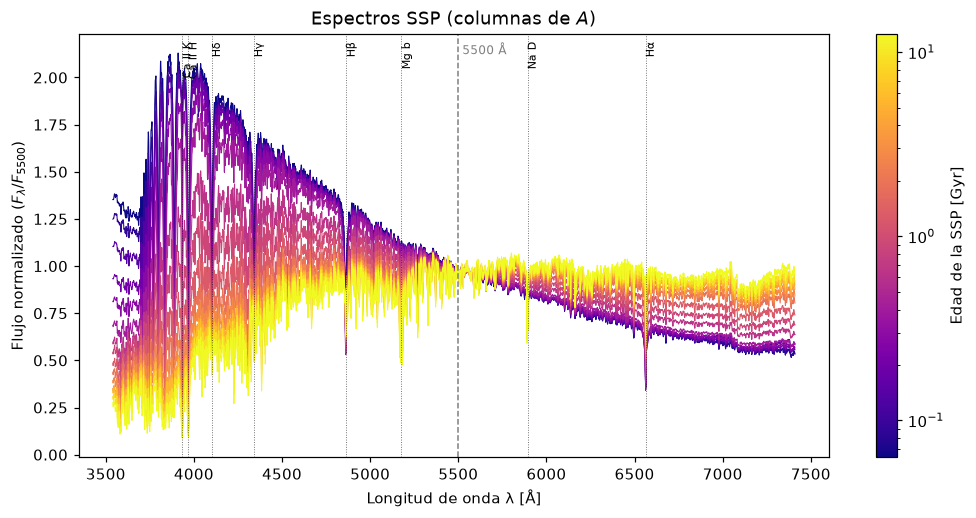

In [3]:
cmap = plt.cm.plasma
norm = LogNorm(edades.min(), edades.max())

lineas = {
    "Ca II K": 3933.7,
    "Ca II H": 3968.5,
    "Hδ": 4101.7,
    "Hγ": 4340.5,
    "Hβ": 4861.3,
    "Mg b": 5175,
    "Na D": 5893,
    "Hα": 6562.8,
}

fig, ax = plt.subplots(figsize=(11, 5))
for j in range(A.shape[1]):
    ax.plot(lam, A[:, j], color=cmap(norm(edades[j])), linewidth=0.7)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Edad de la SSP [Gyr]")

ax.axvline(5500, color="gray", linestyle="--", linewidth=1)
ax.text(5500, 0.98, " 5500 Å", color="gray", fontsize=8, ha="left", va="top",
        transform=ax.get_xaxis_transform())
for nombre, longitud in lineas.items():
    ax.axvline(longitud, color="k", linestyle=":", linewidth=0.6, alpha=0.6)
    ax.text(longitud, 0.98, nombre, rotation=90, fontsize=7, ha="left", va="top",
            transform=ax.get_xaxis_transform())

ax.set_xlabel("Longitud de onda λ [Å]")
ax.set_ylabel(r"Flujo normalizado ($F_\lambda / F_{5500}$)")
ax.set_title("Espectros SSP (columnas de $A$)")
fig.savefig(FIG / "01_ssp_espectros.png")
plt.show()

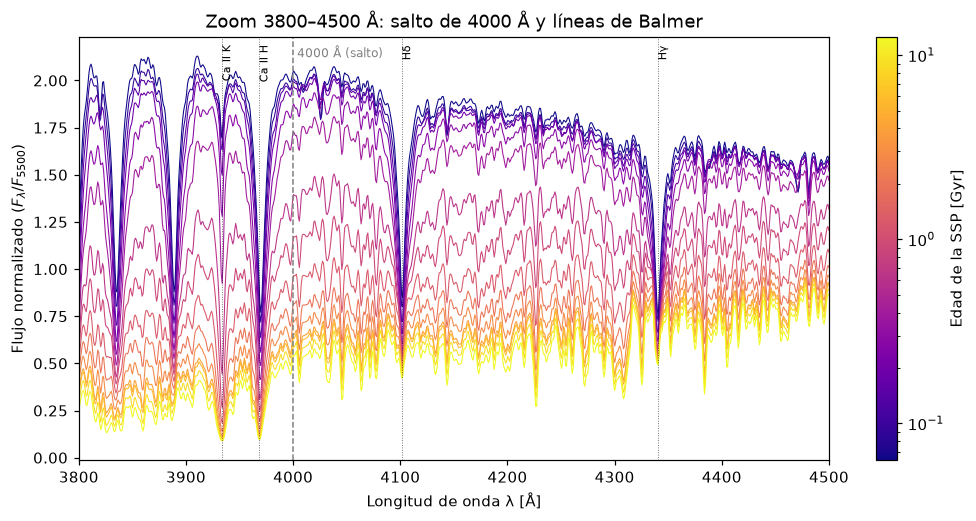

In [4]:
mascara = (lam >= 3800) & (lam <= 4500)

fig, ax = plt.subplots(figsize=(11, 5))
for j in range(A.shape[1]):
    ax.plot(lam[mascara], A[mascara, j], color=cmap(norm(edades[j])), linewidth=0.7)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Edad de la SSP [Gyr]")

ax.axvline(4000, color="gray", linestyle="--", linewidth=1)
ax.text(4000, 0.98, " 4000 Å (salto)", color="gray", fontsize=8, ha="left", va="top",
        transform=ax.get_xaxis_transform())
for nombre, longitud in lineas.items():
    if 3800 <= longitud <= 4500:
        ax.axvline(longitud, color="k", linestyle=":", linewidth=0.6, alpha=0.6)
        ax.text(longitud, 0.98, nombre, rotation=90, fontsize=7, ha="left", va="top",
                transform=ax.get_xaxis_transform())

ax.set_xlim(3800, 4500)
ax.set_xlabel("Longitud de onda λ [Å]")
ax.set_ylabel(r"Flujo normalizado ($F_\lambda / F_{5500}$)")
ax.set_title("Zoom 3800–4500 Å: salto de 4000 Å y líneas de Balmer")
fig.savefig(FIG / "02_ssp_zoom_4000.png")
plt.show()

## 3. Estructura de $A$: heatmap y correlación entre columnas

- **Heatmap.** Casi toda la variación entre columnas está en la parte azul (λ < 5000 Å). En la mitad roja la matriz es casi uniforme: esas filas aportan poca información para separar edades.
- **Correlación.** Las columnas vecinas tienen una correlación de al menos 0,90 y aparecen dos bloques casi colineales: el de las jóvenes (0,06–0,4 Gyr) y, sobre todo, el de las viejas (2–12,6 Gyr), con correlaciones de 0,98 a 1,00. Las jóvenes y las viejas llegan a estar anticorrelacionadas (−0,67 entre 0,063 y 12,6 Gyr): normalizadas en 5500 Å, unas caen hacia el azul y las otras suben.
- **Implicancia.** Si las columnas son casi linealmente dependientes, $A$ tiene rango completo (15), pero está **mal condicionada**: algunas combinaciones $Ax$ con $x$ muy distintos producen espectros muy parecidos. Es esperable que perturbaciones chicas en $b$ produzcan cambios grandes en la estimación de $x$, sobre todo repartiendo peso entre edades vecinas. Esto se cuantifica con la SVD en el ítem 3.

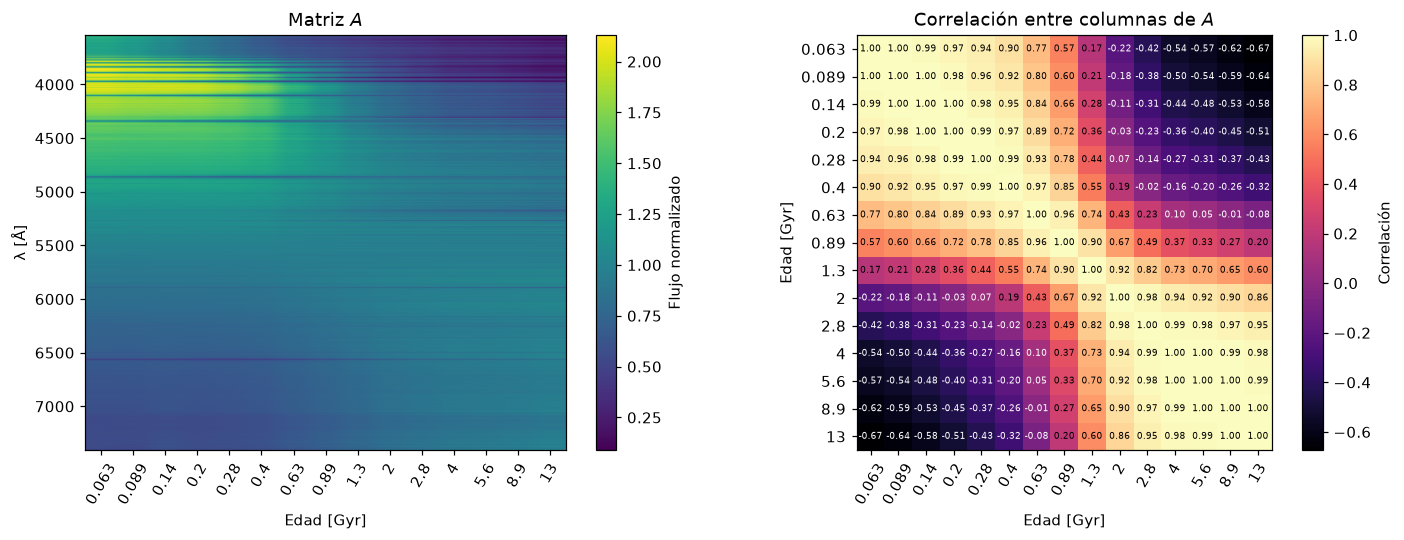

Mínima correlación entre columnas adyacentes: 0.9029
Mínima correlación global: -0.674 entre las edades 0.0631 y 12.5893 Gyr


In [5]:
etiquetas_edad = [f"{e:.2g}" for e in edades]
C = np.corrcoef(A.T)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

im1 = ax1.imshow(A, aspect="auto", cmap="viridis", extent=[-0.5, 14.5, lam.max(), lam.min()])
ax1.set_xticks(range(15))
ax1.set_xticklabels(etiquetas_edad, rotation=60)
ax1.set_xlabel("Edad [Gyr]")
ax1.set_ylabel("λ [Å]")
ax1.set_title("Matriz $A$")
cb1 = fig.colorbar(im1, ax=ax1)
cb1.set_label("Flujo normalizado")

im2 = ax2.imshow(C, cmap="magma", vmin=C.min(), vmax=1)
ax2.set_xticks(range(15))
ax2.set_yticks(range(15))
ax2.set_xticklabels(etiquetas_edad, rotation=60)
ax2.set_yticklabels(etiquetas_edad)
ax2.set_xlabel("Edad [Gyr]")
ax2.set_ylabel("Edad [Gyr]")
ax2.set_title("Correlación entre columnas de $A$")
cb2 = fig.colorbar(im2, ax=ax2)
cb2.set_label("Correlación")
umbral = (C.min() + 1) / 2
for i in range(15):
    for j in range(15):
        color_texto = "white" if C[i, j] < umbral else "black"
        ax2.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=6, color=color_texto)

fig.tight_layout()
fig.savefig(FIG / "03_heatmap_correlacion.png")
plt.show()

min_adyacente = min(C[i, i + 1] for i in range(14))
print("Mínima correlación entre columnas adyacentes:", round(float(min_adyacente), 4))
i_min, j_min = np.unravel_index(np.argmin(C), C.shape)
print("Mínima correlación global:", round(float(C[i_min, j_min]), 4),
      "entre las edades", edades[i_min], "y", edades[j_min], "Gyr")

## 4. Espectro medido $b$, espectro ideal y ruido

Definimos el ruido como $e = b - b_{ideal}$ y su nivel como $\eta = \|e\|_2$.

- $\eta \approx 0{,}115$, que en relativo es $\|e\|_2/\|b_{ideal}\|_2 \approx 0{,}19\,\%$. En la escala del espectro, $b$ y $b_{ideal}$ son indistinguibles a simple vista.
- Por píxel: media $\approx 0$ y desvío $\sigma \approx 1{,}75\times10^{-3}$, lo que con flujo $\sim 1$ equivale a una relación señal/ruido de ~570. Se verifica que $\eta \approx \sigma\sqrt{4300}$.
- El histograma se ajusta bien a una normal con la misma media y desvío. El desvío es el mismo en ambas mitades del rango de $\lambda$ (**homocedástico**) y la autocorrelación es ≈ 0 para todo rezago $k \ge 1$ (**ruido blanco**). Es consistente con ruido gaussiano i.i.d. agregado píxel a píxel.
- $\eta$ va a ser la referencia de los ítems siguientes: un ajuste con residuo mucho menor que $\eta$ estaría ajustando ruido. En el ítem 5 es la cota de "espectros indistinguibles".

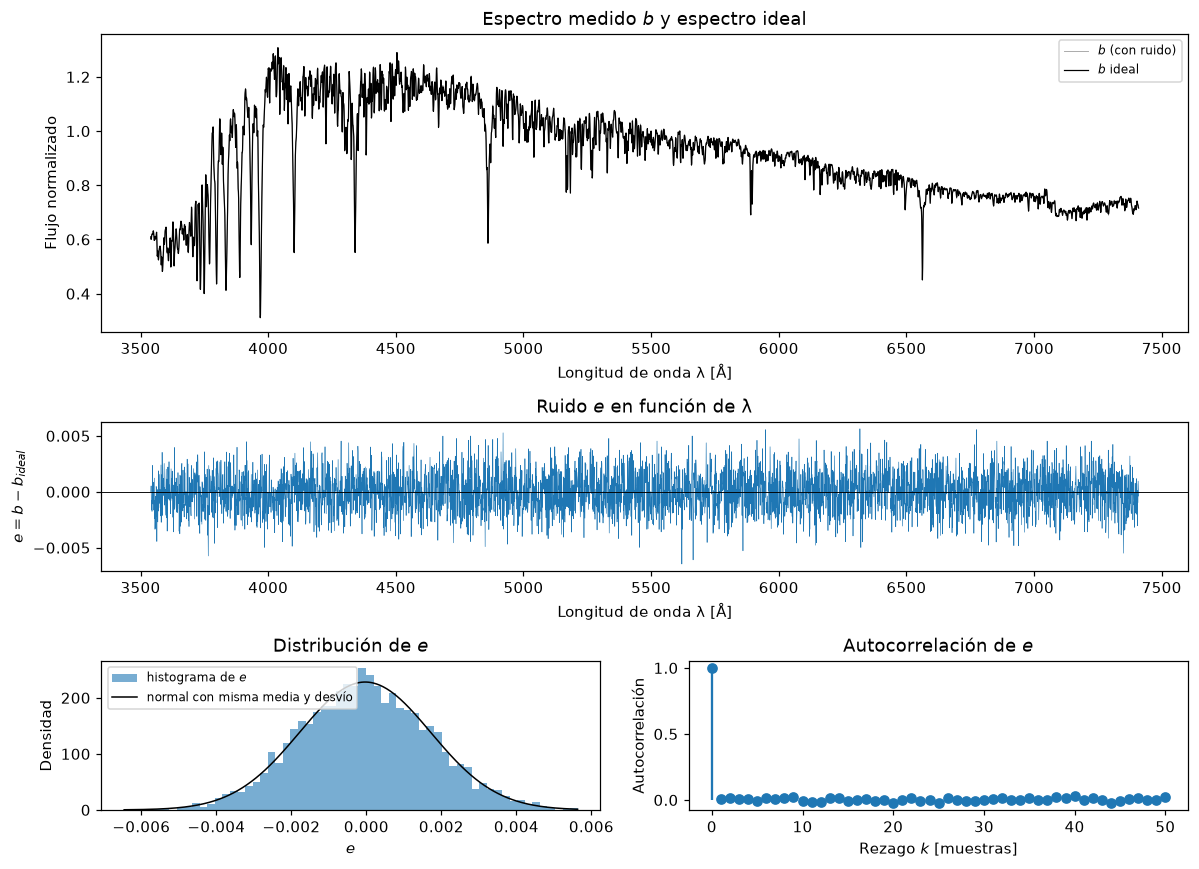

η = ||b - b_ideal||_2 = 0.11465949557718051
η / ||b_ideal||_2 = 0.0018787289452316723
media de e = -3.270072706976866e-05
desvío estándar de e = 0.0017482351083536072
desvío estándar de e, primera mitad de λ = 0.0017410570545361064
desvío estándar de e, segunda mitad de λ = 0.0017549149917279589
autocorrelación de rezago 1 = 0.009365317719607821


In [6]:
e = b - b_ideal
eta = np.linalg.norm(e)
m = e.mean()
s = e.std()

fig, axd = plt.subplot_mosaic(
    [["s", "s"], ["e", "e"], ["h", "ac"]],
    figsize=(11, 8),
    height_ratios=[2, 1, 1],
)

ax = axd["s"]
ax.plot(lam, b, color="gray", alpha=0.7, linewidth=0.6, label="$b$ (con ruido)")
ax.plot(lam, b_ideal, color="k", linewidth=0.8, label="$b$ ideal")
ax.set_xlabel("Longitud de onda λ [Å]")
ax.set_ylabel("Flujo normalizado")
ax.set_title("Espectro medido $b$ y espectro ideal")
ax.legend(fontsize=8)

ax = axd["e"]
ax.plot(lam, e, linewidth=0.4)
ax.axhline(0, color="k", linewidth=0.6)
ax.set_xlabel("Longitud de onda λ [Å]")
ax.set_ylabel("$e = b - b_{ideal}$")
ax.set_title("Ruido $e$ en función de λ")

ax = axd["h"]
ax.hist(e, bins=60, density=True, alpha=0.6, label="histograma de $e$")
xs = np.linspace(e.min(), e.max(), 400)
pdf = np.exp(-0.5 * ((xs - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
ax.plot(xs, pdf, color="k", linewidth=1, label="normal con misma media y desvío")
ax.set_xlabel("$e$")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de $e$")
ax.legend(fontsize=8)

ax = axd["ac"]
K = 50
den = np.dot(e - m, e - m)
ac = np.empty(K + 1)
for k in range(K + 1):
    ac[k] = np.dot(e[:-k or None] - m, e[k:] - m) / den
ax.stem(np.arange(K + 1), ac, basefmt=" ")
ax.set_xlabel("Rezago $k$ [muestras]")
ax.set_ylabel("Autocorrelación")
ax.set_title("Autocorrelación de $e$")

fig.tight_layout()
fig.savefig(FIG / "04_ruido.png")
plt.show()

mitad = len(e) // 2
print("η = ||b - b_ideal||_2 =", eta)
print("η / ||b_ideal||_2 =", eta / np.linalg.norm(b_ideal))
print("media de e =", m)
print("desvío estándar de e =", s)
print("desvío estándar de e, primera mitad de λ =", e[:mitad].std())
print("desvío estándar de e, segunda mitad de λ =", e[mitad:].std())
print("autocorrelación de rezago 1 =", ac[1])

## 5. Composición real $x_{real}$

- $x_{real}$ es una distribución de proporciones: todas positivas y con $\sum_j x_j = 1$. Es unimodal en $\log t$, con el máximo (0,10) entre 0,9 y 2 Gyr, y colas de 0,03–0,05 en los extremos. Ninguna población es despreciable.
- $\|Ax_{real} - b_{ideal}\|_2 \approx 1{,}1\times10^{-8}$ (relativo $\approx 2\times10^{-10}$, compatible con el redondeo de los CSV). Es decir, **$b_{ideal}$ se generó exactamente como $A x_{real}$**: el modelo lineal es exacto y todo el desajuste viene del ruido.
- $\|Ax_{real} - b\|_2 = \eta$: la composición verdadera deja un residuo del tamaño exacto del ruido. Que un método encuentre un $x$ con residuo algo menor que $\eta$ no significa que esté más cerca de $x_{real}$. Ese es el punto central del ítem 2.

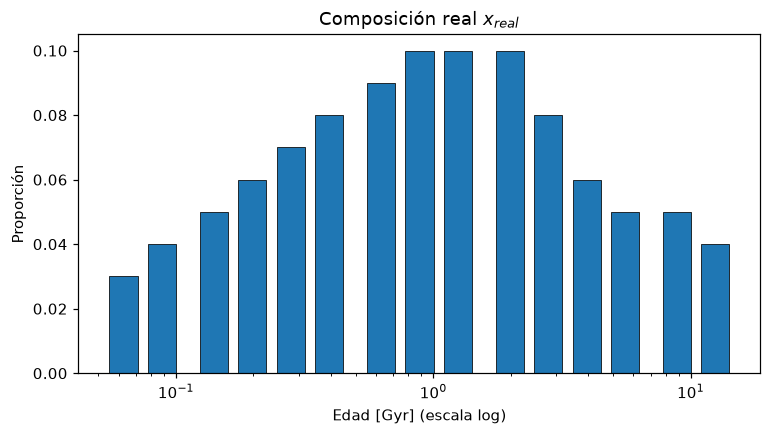

Suma de x_real: 1.0
||A x_real - b_ideal||_2 = 1.0926746815144206e-08
||A x_real - b_ideal||_2 / ||b_ideal||_2 = 1.7903790188062683e-10
||A x_real - b||_2 = 0.11465949561228872
η = ||b - b_ideal||_2 = 0.11465949557718051


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ancho = edades * 0.25
ax.bar(edades, x_real, width=ancho, color="C0", edgecolor="k", linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("Edad [Gyr] (escala log)")
ax.set_ylabel("Proporción")
ax.set_title("Composición real $x_{real}$")
fig.savefig(FIG / "05_x_real.png")
plt.show()

print("Suma de x_real:", x_real.sum())
error_abs = np.linalg.norm(A @ x_real - b_ideal)
print("||A x_real - b_ideal||_2 =", error_abs)
print("||A x_real - b_ideal||_2 / ||b_ideal||_2 =", error_abs / np.linalg.norm(b_ideal))
print("||A x_real - b||_2 =", np.linalg.norm(A @ x_real - b))
print("η = ||b - b_ideal||_2 =", eta)

## Conclusiones del ejercicio 1

1. $A \in \mathbb{R}^{4300\times 15}$: cada columna es un espectro SSP normalizado en 5500 Å y cada fila es una longitud de onda. Al ser $m \gg n$, el sistema $Ax \approx b$ es sobredeterminado y se resuelve por cuadrados mínimos.
2. Los espectros varían de forma suave y monótona con la edad. Las columnas vecinas están fuertemente correlacionadas (≥ 0,90) y las de edades viejas son casi colineales. Por eso $A$ tiene rango completo pero se espera que esté **mal condicionada**.
3. El ruido es gaussiano, blanco y homocedástico, de nivel $\eta = \|b - b_{ideal}\|_2 \approx 0{,}115$ (≈ 0,19 % de la señal).
4. $b_{ideal} = A x_{real}$ de forma exacta, así que la dificultad para recuperar $x_{real}$ viene solo de la combinación ruido + mal condicionamiento. Eso es lo que estudian los ítems 2 a 5.